# Importing Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Configuration

In [3]:
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f"{x:.3f}")
sns.set_theme(style = 'darkgrid')


RANDOM_STATE = 42
CSV_PATH = '../data/raw/housing.csv'

# Load data

In [4]:
df = pd.read_csv(CSV_PATH)

# Basic Info

In [5]:
df.shape

(20640, 10)

In [6]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,452600.000,NEAR BAY
1,-122.220,37.860,21.000,7099.000,1106.000,2401.000,1138.000,8.301,358500.000,NEAR BAY
2,-122.240,37.850,52.000,1467.000,190.000,496.000,177.000,7.257,352100.000,NEAR BAY
3,-122.250,37.850,52.000,1274.000,235.000,558.000,219.000,5.643,341300.000,NEAR BAY
4,-122.250,37.850,52.000,1627.000,280.000,565.000,259.000,3.846,342200.000,NEAR BAY


In [13]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [38]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
TARGET_COL = 'median_house_value'

# Missing value Analysis

In [39]:
df.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

## Encoded missing values

In [43]:
for col in df.columns:
    print(df[col].value_counts().head())
    print('='*25)

longitude
-118.310    162
-118.300    160
-118.290    148
-118.270    144
-118.320    142
Name: count, dtype: int64
latitude
34.060    244
34.050    236
34.080    234
34.070    231
34.040    221
Name: count, dtype: int64
housing_median_age
52.000    1273
36.000     862
35.000     824
16.000     771
17.000     698
Name: count, dtype: int64
total_rooms
1527.000    18
1613.000    17
1582.000    17
2127.000    16
1471.000    15
Name: count, dtype: int64
total_bedrooms
280.000    55
331.000    51
345.000    50
393.000    49
343.000    49
Name: count, dtype: int64
population
891.000     25
1227.000    24
761.000     24
850.000     24
1052.000    24
Name: count, dtype: int64
households
306.000    57
335.000    56
386.000    56
282.000    55
429.000    54
Name: count, dtype: int64
median_income
3.125     49
15.000    49
2.875     46
2.625     44
4.125     44
Name: count, dtype: int64
median_house_value
500001.000    965
137500.000    122
162500.000    117
112500.000    103
187500.000     93
Na

median_house_value

- 500001.000    965
- 137500.000    122
- 162500.000    117
- 112500.000    103
- 187500.000     93

Name: count, dtype: int64

Here it can be seen that there are 965 houses of same price which looks abit odd , so it looks like the dta is upper capped 

Note: Total bedrooms has missing values  

# Statistical Summary

In [37]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000,20640.000,20640.000,20640.000,20433.000,20640.000,20640.000,20640.000,20640.000
mean,-119.570,35.632,28.639,2635.763,537.871,1425.477,499.540,3.871,206855.817
std,2.004,2.136,12.586,2181.615,421.385,1132.462,382.330,1.900,115395.616
min,-124.350,32.540,1.000,2.000,1.000,3.000,1.000,0.500,14999.000
25%,-121.800,33.930,18.000,1447.750,296.000,787.000,280.000,2.563,119600.000
50%,-118.490,34.260,29.000,2127.000,435.000,1166.000,409.000,3.535,179700.000
75%,-118.010,37.710,37.000,3148.000,647.000,1725.000,605.000,4.743,264725.000
max,-114.310,41.950,52.000,39320.000,6445.000,35682.000,6082.000,15.000,500001.000


# Checking for duplicates 

In [44]:
df.duplicated().sum()

np.int64(0)

No duplicates

# Target Variable Analysis

In [45]:
df[TARGET_COL].info()

<class 'pandas.Series'>
RangeIndex: 20640 entries, 0 to 20639
Series name: median_house_value
Non-Null Count  Dtype  
--------------  -----  
20640 non-null  float64
dtypes: float64(1)
memory usage: 161.4 KB


In [46]:
df[TARGET_COL].describe()

count    20640.000
mean    206855.817
std     115395.616
min      14999.000
25%     119600.000
50%     179700.000
75%     264725.000
max     500001.000
Name: median_house_value, dtype: float64

# Visualizing distribution

## Target_col

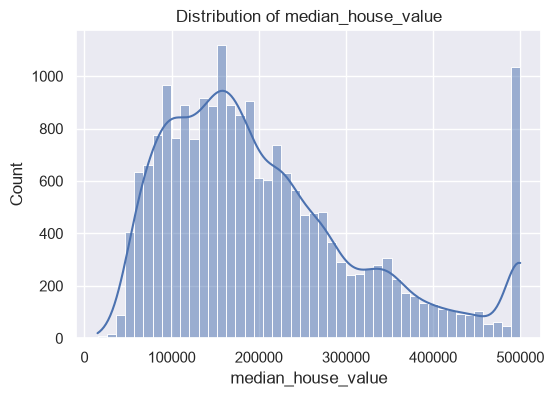

In [50]:
plt.figure(figsize=(6,4))
sns.histplot(x=TARGET_COL , data=df , kde=True)
plt.title(f"Distribution of {TARGET_COL}")
plt.show()

## Features

### Categorical columns

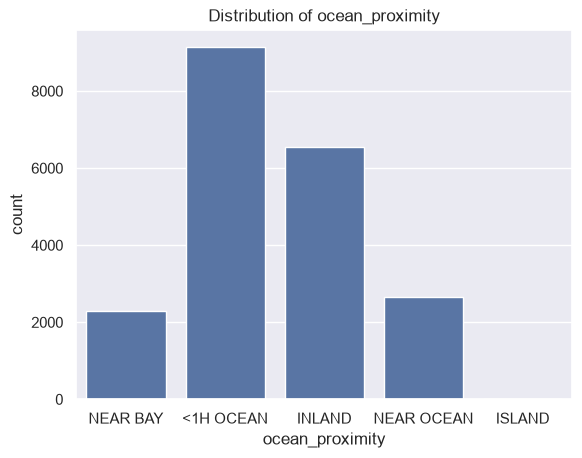

In [56]:
plt.Figure(figsize=(6,4))
for cols in cat_cols:
    sns.countplot(data=df , x = cols  )
    plt.title(f"Distribution of {col}")
    plt.show()

### Numerical Cols

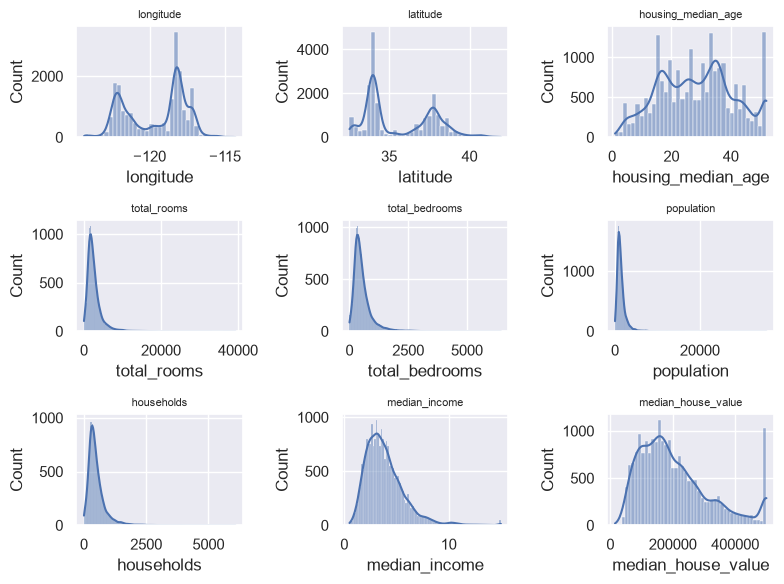

In [59]:
# for col in num_cols:
#     sns.histplot(x = col , data=df , kde = True)
#     plt.title(f"Distribution of {col}")
#     plt.show()

# Another way
fig , axes = plt.subplots(3,3,figsize=(8,6))
axes = axes.flatten()
for i ,col in enumerate(num_cols):
    sns.histplot(df[col] , kde = True ,ax = axes[i] )
    axes[i].set_title(col , fontsize = 8)

plt.tight_layout()
plt.show()

# Correlation

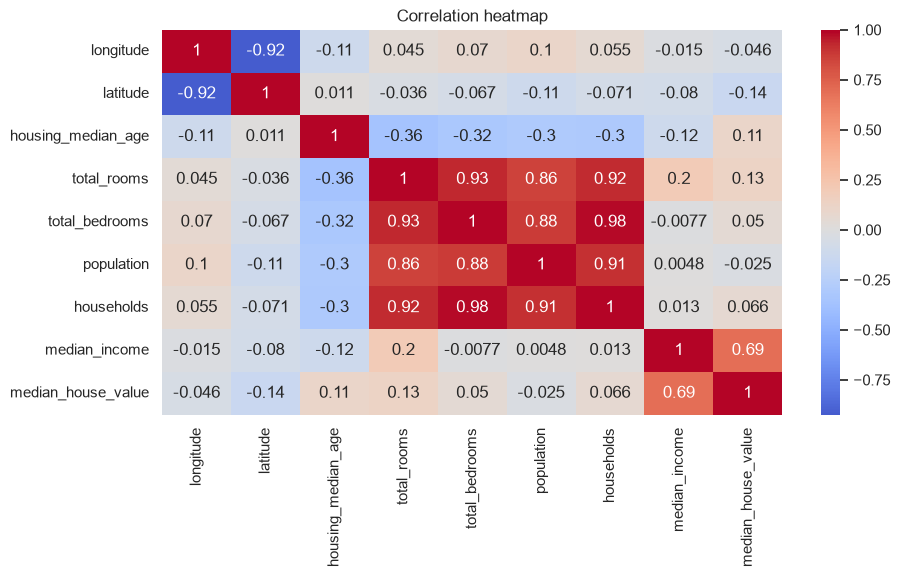

In [72]:
plt.figure(figsize = (10,5))
sns.heatmap(
    df[num_cols].corr(),
    annot = True,
    cmap = 'coolwarm',
    center = 0
)
plt.title("Correlation heatmap")
plt.show()

In [86]:
# Calculate correlations with target
target_corr = df[num_cols].corr()[TARGET_COL].sort_values(ascending=False)
filtered_corr = target_corr[(target_corr>0.1)]
filtered_corr.index.tolist()

['median_house_value', 'median_income', 'total_rooms', 'housing_median_age']